# 1. Introduction

The dataset used in this project is the Spotify Dataset 1921-2020 available on Kaggle. It contains detailed information on 586,672 tracks (the Kaggle listing calls it "600k tracks"), providing a rich resource for analyzing audio features and their relationship to track popularity.

Dataset Link: https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks?select=tracks.csv

### Key Features of the Dataset

**duration_ms**: The duration of the track in milliseconds.

**key**: The overall key of the track, represented as integers based on standard Pitch Class notation (e.g., 0 = C, 1 = C♯/D♭, etc.). A value of -1 indicates no key was detected.

**mode**: Indicates whether the track is in a major (1) or minor (0) scale.

**time_signature**: The estimated time signature (number of beats per bar).

**acousticness**: A confidence measure (0.0 to 1.0) of whether the track is acoustic, where 1.0 indicates high confidence.

**danceability**: A score (0.0 to 1.0) reflecting how suitable a track is for dancing, based on tempo, rhythm, and beat regularity.

**energy**: A perceptual measure of intensity and activity (0.0 to 1.0), with higher values indicating faster, louder, and more dynamic tracks.

**instrumentalness**: Predicts the likelihood of a track containing no vocals. Values closer to 1.0 indicate higher confidence that the track is instrumental.

**liveness**: Measures the presence of a live audience in the recording, with values above 0.8 suggesting a live performance.

**loudness**: The average loudness of a track in decibels (dB), typically ranging from -60 to 0 dB.

**speechiness**: Speechiness detects the presence of spoken words in a track. The more exclusively speech-like the recording (e.g. talk show, audio book, poetry), the closer to 1.0 the attribute value. Values above 0.66 describe tracks that are probably made entirely of spoken words. Values between 0.33 and 0.66 describe tracks that may contain both music and speech, either in sections or layered, including such cases as rap music. Values below 0.33 most likely represent music and other non-speech-like tracks.

**valence**: A measure from 0.0 to 1.0 describing the musical positiveness conveyed by a track. Tracks with high valence sound more positive (e.g. happy, cheerful, euphoric), while tracks with low valence sound more negative (e.g. sad, depressed, angry).

**tempo**: The overall estimated tempo of a track in beats per minute (BPM). In musical terminology, tempo is the speed or pace of a given piece and derives directly from the average beat duration.

**id**: The Spotify ID for the track.

**type**: The object type: “audio_features”

**popularity**: A score (0 to 100) representing the track's popularity, influenced by total and recent plays. Note that the popularity metric may lag real-time data by a few days.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

## Loading in the Data

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yamaerenay/spotify-dataset-19212020-600k-tracks")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'spotify-dataset-19212020-600k-tracks' dataset.
Path to dataset files: /kaggle/input/spotify-dataset-19212020-600k-tracks


In [3]:
df = pd.read_csv(f"{path}/tracks.csv")
df

,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,35iwgR4jXetI318WEWsa1Q,Carve,6,126903,0,['Uli'],['45tIt06XoI0Iio4LBEVpls'],1922-02-22,0.645,0.4450,0,-13.338,1,0.4510,0.674,0.744000,0.1510,0.1270,104.851,3
1,021ht4sdgPcrDgSk7JTbKY,Capítulo 2.16 - Banquero Anarquista,0,98200,0,['Fernando Pessoa'],['14jtPCOoNZwquk5wd9DxrY'],1922-06-01,0.695,0.2630,0,-22.136,1,0.9570,0.797,0.000000,0.1480,0.6550,102.009,1
2,07A5yehtSnoedViJAZkNnc,Vivo para Quererte - Remasterizado,0,181640,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.434,0.1770,1,-21.180,1,0.0512,0.994,0.021800,0.2120,0.4570,130.418,5
3,08FmqUhxtyLTn6pAh6bk45,El Prisionero - Remasterizado,0,176907,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.321,0.0946,7,-27.961,1,0.0504,0.995,0.918000,0.1040,0.3970,169.980,3
4,08y9GfoqCWfOGsKdwojr5e,Lady of the Evening,0,163080,0,['Dick Haymes'],['3BiJGZsyX9sJchTqcSA7Su'],1922,0.402,0.1580,3,-16.900,0,0.0390,0.989,0.130000,0.3110,0.1960,103.220,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
586667,5rgu12WBIHQtvej2MdHSH0,云与海,50,258267,0,['阿YueYue'],['1QLBXKM5GCpyQQSVMNZqrZ'],2020-09-26,0.560,0.5180,0,-7.471,0,0.0292,0.785,0.000000,0.0648,0.2110,131.896,4
586668,0NuWgxEp51CutD2pJoF4OM,blind,72,153293,0,['ROLE MODEL'],['1dy5WNgIKQU6ezkpZs4y8z'],2020-10-21,0.765,0.6630,0,-5.223,1,0.0652,0.141,0.000297,0.0924,0.6860,150.091,4
586669,27Y1N4Q4U3EfDU5Ubw8ws2,What They'll Say About Us,70,187601,0,['FINNEAS'],['37M5pPGs6V1fchFJSgCguX'],2020-09-02,0.535,0.3140,7,-12.823,0,0.0408,0.895,0.000150,0.0874,0.0663,145.095,4
586670,45XJsGpFTyzbzeWK8VzR8S,A Day At A Time,58,142003,0,"['Gentle Bones', 'Clara Benin']","['4jGPdu95icCKVF31CcFKbS', '5ebPSE9YI5aLeZ1Z2g...",2021-03-05,0.696,0.6150,10,-6.212,1,0.0345,0.206,0.000003,0.3050,0.4380,90.029,4


## Cleaning Data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 586672 entries, 0 to 586671
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                586672 non-null  object 
 1   name              586601 non-null  object 
 2   popularity        586672 non-null  int64  
 3   duration_ms       586672 non-null  int64  
 4   explicit          586672 non-null  int64  
 5   artists           586672 non-null  object 
 6   id_artists        586672 non-null  object 
 7   release_date      586672 non-null  object 
 8   danceability      586672 non-null  float64
 9   energy            586672 non-null  float64
 10  key               586672 non-null  int64  
 11  loudness          586672 non-null  float64
 12  mode              586672 non-null  int64  
 13  speechiness       586672 non-null  float64
 14  acousticness      586672 non-null  float64
 15  instrumentalness  586672 non-null  float64
 16  liveness          58

In [5]:
df['release_date'] = pd.to_datetime(df['release_date'], format='mixed', errors='coerce')

# format='mixed' is required: release_date mixes 'YYYY-MM-DD', 'YYYY-MM' and 'YYYY' formats,
# and the default parser would turn every non matching row into NaT and silently drop it later
df['year'] = df['release_date'].dt.year
df

,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,year
0,35iwgR4jXetI318WEWsa1Q,Carve,6,126903,0,['Uli'],['45tIt06XoI0Iio4LBEVpls'],1922-02-22,0.645,0.4450,...,-13.338,1,0.4510,0.674,0.744000,0.1510,0.1270,104.851,3,1922
1,021ht4sdgPcrDgSk7JTbKY,Capítulo 2.16 - Banquero Anarquista,0,98200,0,['Fernando Pessoa'],['14jtPCOoNZwquk5wd9DxrY'],1922-06-01,0.695,0.2630,...,-22.136,1,0.9570,0.797,0.000000,0.1480,0.6550,102.009,1,1922
2,07A5yehtSnoedViJAZkNnc,Vivo para Quererte - Remasterizado,0,181640,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.434,0.1770,...,-21.180,1,0.0512,0.994,0.021800,0.2120,0.4570,130.418,5,1922
3,08FmqUhxtyLTn6pAh6bk45,El Prisionero - Remasterizado,0,176907,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.321,0.0946,...,-27.961,1,0.0504,0.995,0.918000,0.1040,0.3970,169.980,3,1922
4,08y9GfoqCWfOGsKdwojr5e,Lady of the Evening,0,163080,0,['Dick Haymes'],['3BiJGZsyX9sJchTqcSA7Su'],1922-01-01,0.402,0.1580,...,-16.900,0,0.0390,0.989,0.130000,0.3110,0.1960,103.220,4,1922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
586667,5rgu12WBIHQtvej2MdHSH0,云与海,50,258267,0,['阿YueYue'],['1QLBXKM5GCpyQQSVMNZqrZ'],2020-09-26,0.560,0.5180,...,-7.471,0,0.0292,0.785,0.000000,0.0648,0.2110,131.896,4,2020
586668,0NuWgxEp51CutD2pJoF4OM,blind,72,153293,0,['ROLE MODEL'],['1dy5WNgIKQU6ezkpZs4y8z'],2020-10-21,0.765,0.6630,...,-5.223,1,0.0652,0.141,0.000297,0.0924,0.6860,150.091,4,2020
586669,27Y1N4Q4U3EfDU5Ubw8ws2,What They'll Say About Us,70,187601,0,['FINNEAS'],['37M5pPGs6V1fchFJSgCguX'],2020-09-02,0.535,0.3140,...,-12.823,0,0.0408,0.895,0.000150,0.0874,0.0663,145.095,4,2020
586670,45XJsGpFTyzbzeWK8VzR8S,A Day At A Time,58,142003,0,"['Gentle Bones', 'Clara Benin']","['4jGPdu95icCKVF31CcFKbS', '5ebPSE9YI5aLeZ1Z2g...",2021-03-05,0.696,0.6150,...,-6.212,1,0.0345,0.206,0.000003,0.3050,0.4380,90.029,4,2021


In [6]:
df.isnull().sum()

,0
id,0
name,71
popularity,0
duration_ms,0
explicit,0
artists,0
id_artists,0
release_date,0
danceability,0
energy,0


In [7]:
# removing nulls (only the 71 tracks with no name should be dropped now)
n_before = len(df)
df = df.dropna().copy()
print(f'Dropped {n_before - len(df):,} of {n_before:,} rows with missing values; {len(df):,} remain')

Dropped 71 of 586,672 rows with missing values; 586,601 remain


In [8]:
df['artists'] = df['artists'].str.replace("'","", regex=False)
df['artists'] = df['artists'].str.replace("[","", regex=False)
df['artists'] = df['artists'].str.replace("]","", regex=False)
df.head()

,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,year
0,35iwgR4jXetI318WEWsa1Q,Carve,6,126903,0,Uli,['45tIt06XoI0Iio4LBEVpls'],1922-02-22,0.645,0.4450,...,-13.338,1,0.4510,0.674,0.7440,0.151,0.127,104.851,3,1922
1,021ht4sdgPcrDgSk7JTbKY,Capítulo 2.16 - Banquero Anarquista,0,98200,0,Fernando Pessoa,['14jtPCOoNZwquk5wd9DxrY'],1922-06-01,0.695,0.2630,...,-22.136,1,0.9570,0.797,0.0000,0.148,0.655,102.009,1,1922
2,07A5yehtSnoedViJAZkNnc,Vivo para Quererte - Remasterizado,0,181640,0,Ignacio Corsini,['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.434,0.1770,...,-21.180,1,0.0512,0.994,0.0218,0.212,0.457,130.418,5,1922
3,08FmqUhxtyLTn6pAh6bk45,El Prisionero - Remasterizado,0,176907,0,Ignacio Corsini,['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.321,0.0946,...,-27.961,1,0.0504,0.995,0.9180,0.104,0.397,169.980,3,1922
4,08y9GfoqCWfOGsKdwojr5e,Lady of the Evening,0,163080,0,Dick Haymes,['3BiJGZsyX9sJchTqcSA7Su'],1922-01-01,0.402,0.1580,...,-16.900,0,0.0390,0.989,0.1300,0.311,0.196,103.220,4,1922


In [9]:
df.shape

(586601, 21)

# Exploratory Data analysis

### Correlation Analysis

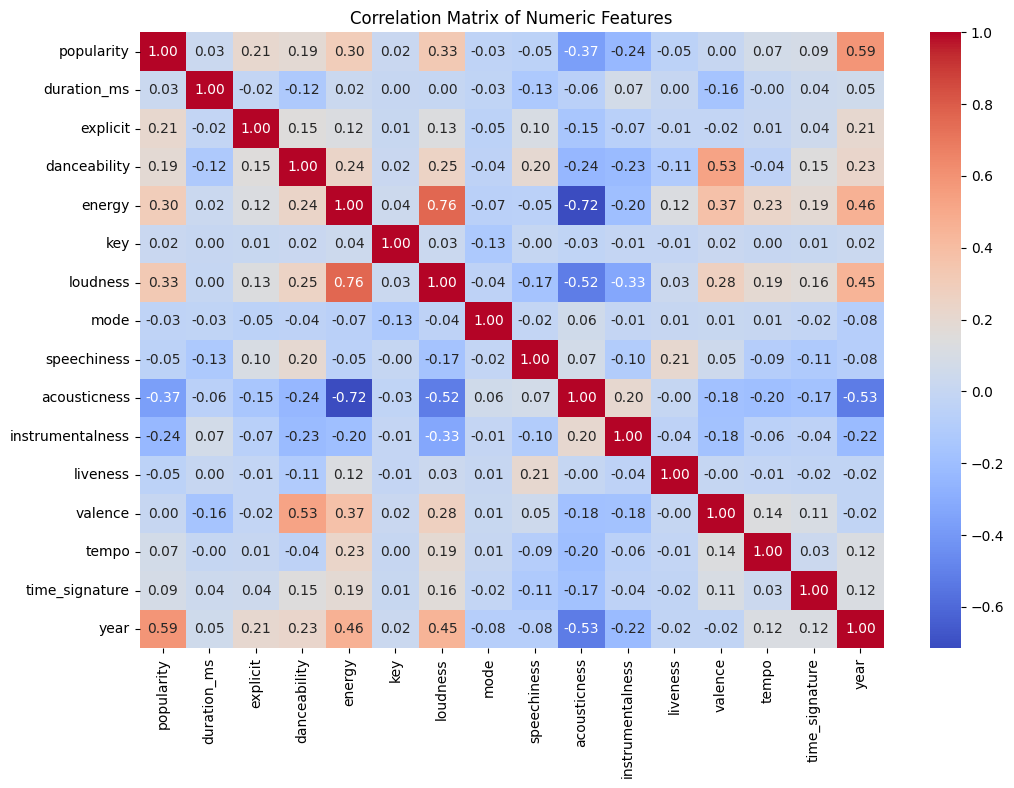

In [10]:
# Select only numeric columns
numeric_data = df.select_dtypes(include=[np.number])

# Compute correlation matrix
correlation_matrix = numeric_data.corr()

# Plot heatmap for the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

**Takeaways from the correlation matrix**

- Release year has the strongest correlation with popularity (roughly 0.6), stronger than any audio feature. Loudness, energy, danceability, and explicit content correlate positively with popularity at roughly 0.2 to 0.3, and acousticness and instrumentalness negatively.
- The audio features are tangled together: energy and loudness rise together (roughly 0.75), and energy and acousticness move in opposite directions (roughly -0.7).
- Release year also correlates with energy, loudness, and acousticness, so part of each feature's correlation with popularity is a release year effect. The regression section later separates the two.
- These are pairwise linear correlations and say nothing about causation.

### Distribution of Audio Features

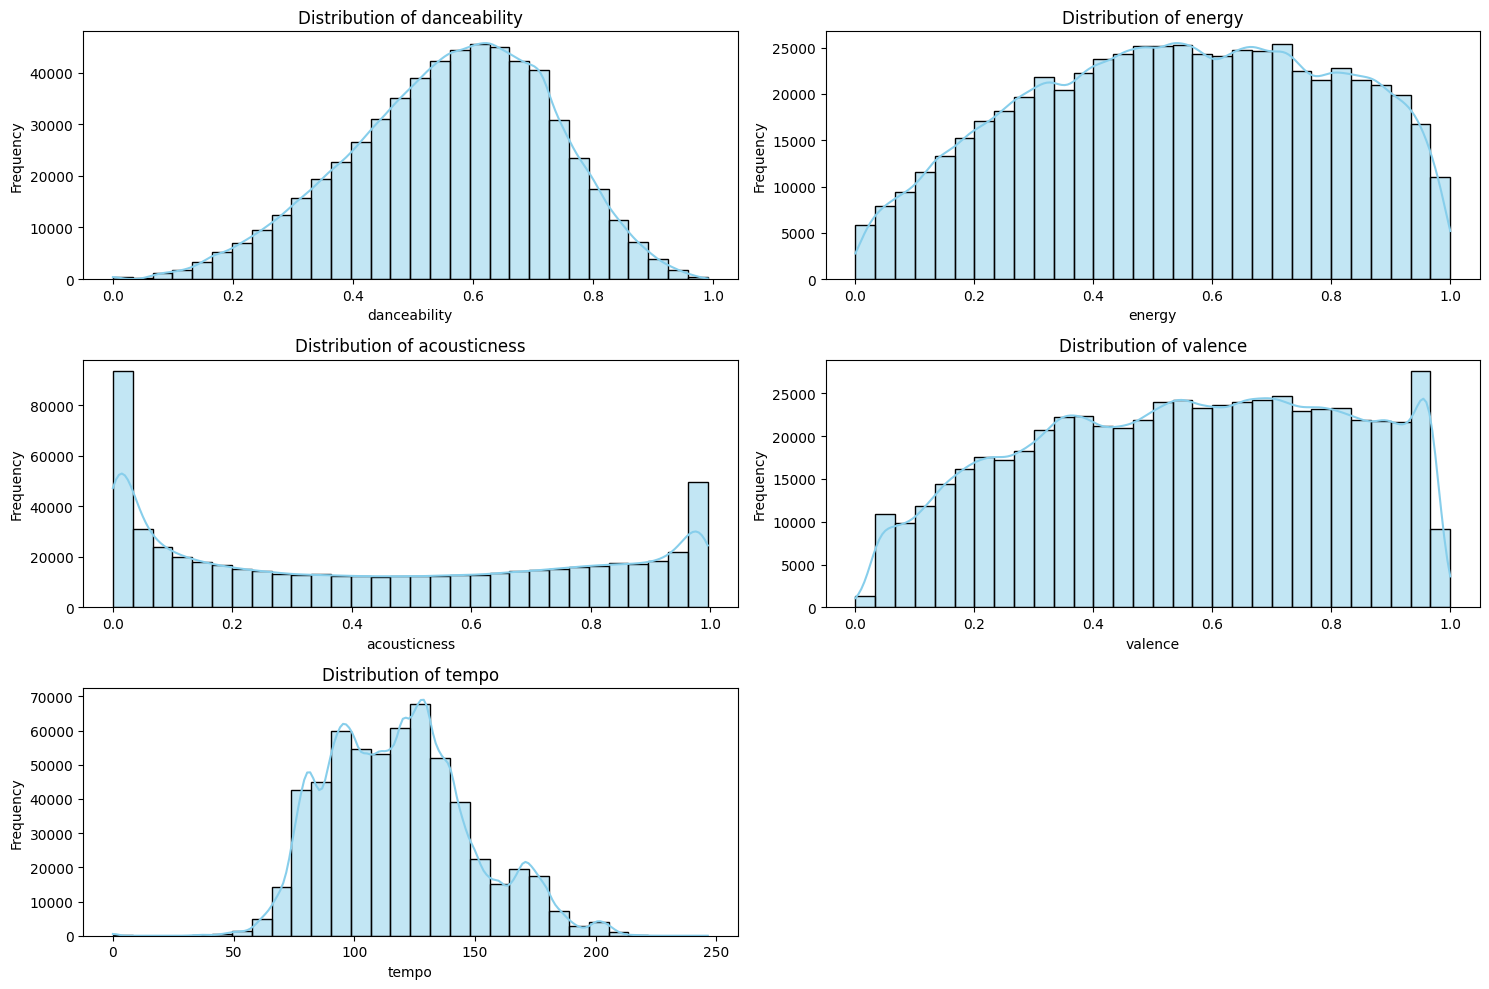

In [11]:
# Plot distributions of key audio features
features_to_plot = ['danceability', 'energy', 'acousticness', 'valence', 'tempo']
plt.figure(figsize=(15, 10))

for i, feature in enumerate(features_to_plot):
    plt.subplot(3, 2, i + 1)
    sns.histplot(df[feature], kde=True, color='skyblue', bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Popularity Distribution Across Key

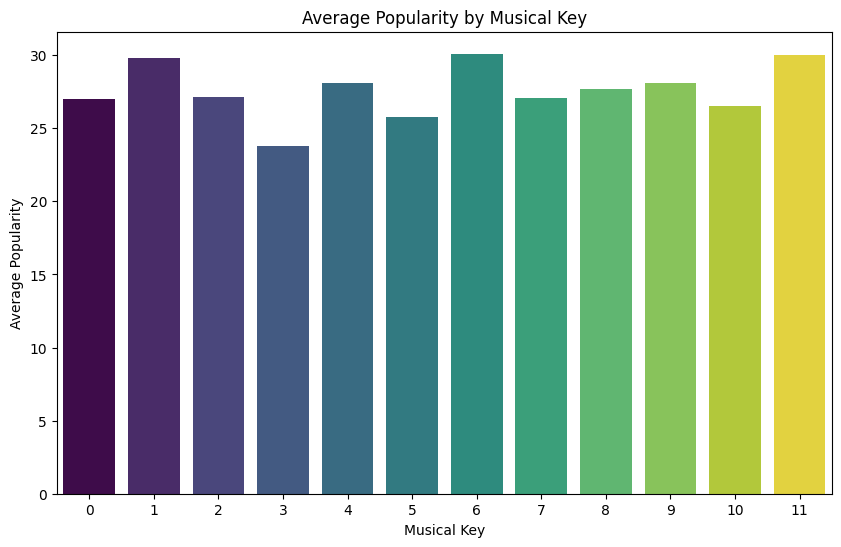

In [12]:
# Popularity grouped by musical key
popularity_by_key = df.groupby('key')['popularity'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='key', y='popularity', data=popularity_by_key, hue='key', palette='viridis', legend=False)
plt.title('Average Popularity by Musical Key')
plt.xlabel('Musical Key')
plt.ylabel('Average Popularity')
plt.show()

**Takeaway: musical key**

Average popularity ranges from about 24 (key 3) to about 30 (keys 1, 6 and 11), with no ordering that follows the musical structure. These gaps are modest next to the effects of release year and explicit content found later. This is a plain comparison of means with no significance test, so key is not used as a predictor in the rest of the analysis.

### Music attributes of songs over the years

Text(0.5, 0, 'Year')

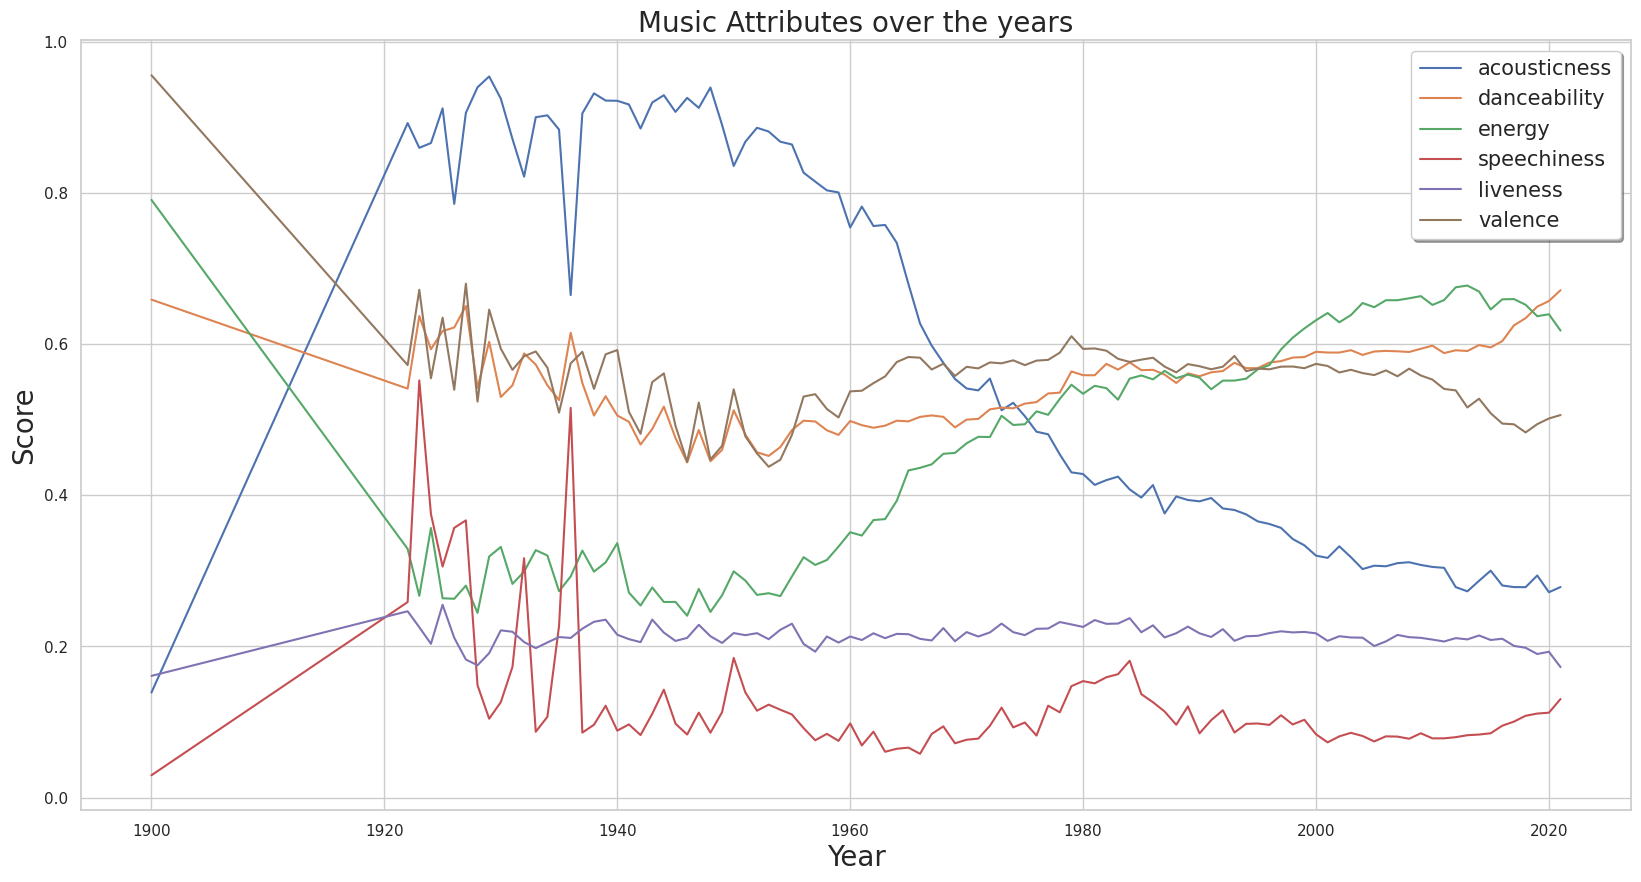

In [13]:
plt.figure(figsize=(20, 10))
sns.set(style="whitegrid")
# the columns that we are interested in
target_cols = ["acousticness","danceability","energy","speechiness","liveness","valence"]
for c in target_cols:
    # group the data by year, and plot the mean score of all music in that year
    x = df.groupby("year")[c].mean()
    ax= sns.lineplot(x=x.index,y=x,label=c)

ax.set_title('Music Attributes over the years', fontsize = 20)
ax.legend(fancybox=True, framealpha=1, shadow=True, prop={'size': 15}, loc = 'upper right')
ax.set_ylabel('Score', fontsize = 20)
ax.set_xlabel('Year', fontsize = 20)

**Takeaways: how track attributes changed over time**

- **Acousticness:** very high (roughly 0.85 to 0.95) until the mid 1950s, then fell sharply through the 1960s and kept declining to around 0.3 by the 2000s.
- **Energy:** moved the other way, from roughly 0.3 in the 1940s and 1950s up to about 0.65 by the 2010s. Acousticness and energy have mirror image trends, consistent with their strong negative correlation.
- **Danceability:** stayed in a narrow band of about 0.5 to 0.6 for most of the century, then rose in the most recent years of the data to roughly 0.65 or higher.
- **Speechiness:** extremely volatile before about 1940, then low (mostly below 0.2) for the rest of the period.
- **Liveness:** fairly flat at around 0.2 throughout, with a slight decline in the most recent years.
- **Valence (musical positivity):** roughly stable at 0.55 to 0.6 from the 1960s until about 2010, then drifting down toward 0.5.

**Caution on the early years:** before about 1940 the yearly averages swing wildly, and the straight line from 1900 to the early 1920s connects a handful of tracks. These years have too little data to support conclusions.

These are descriptive trends. The plot shows what changed, not why.

### Loudness

Text(0.5, 0, 'Year')

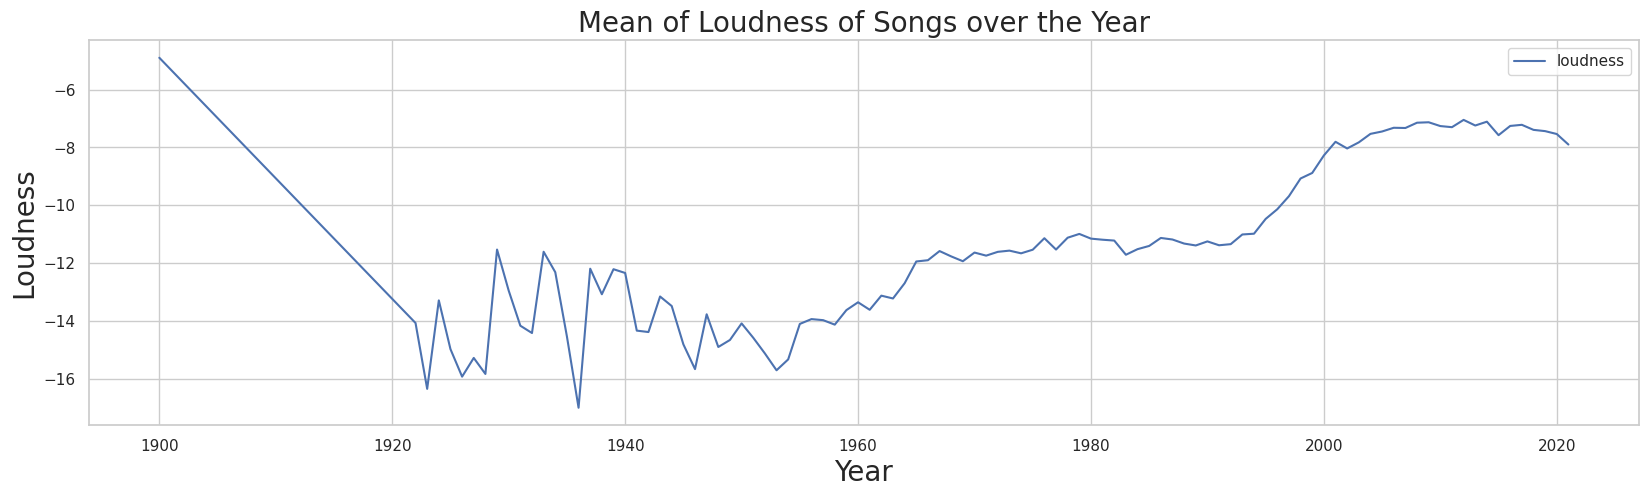

In [14]:
plt.figure(figsize=(20, 5))
# mean loudness over year
x = df.groupby('year')["loudness"].mean()
ax = sns.lineplot(x= x.index, y=x, label="loudness")

# set axis label and titles
ax.set_title('Mean of Loudness of Songs over the Year', fontsize = 20)
ax.set_ylabel('Loudness', fontsize = 20)
ax.set_xlabel('Year', fontsize = 20)

**Takeaway: loudness over time**

Average loudness was low and volatile before about 1950, rose slowly from roughly -14 dB in the 1950s to about -11 dB by the 1970s, stayed near there through the early 1990s, then rose sharply from the mid 1990s to about -7 or -8 dB by the mid 2000s, and has been roughly flat since.

This plot does not show why. Changes in recording and production practice and in the mix of genres are plausible explanations, but neither is tested here. Loudness is also strongly correlated with energy (roughly 0.75 in the heatmap), so the loudness and energy trends largely describe the same shift.

### Relationship between year and popularity

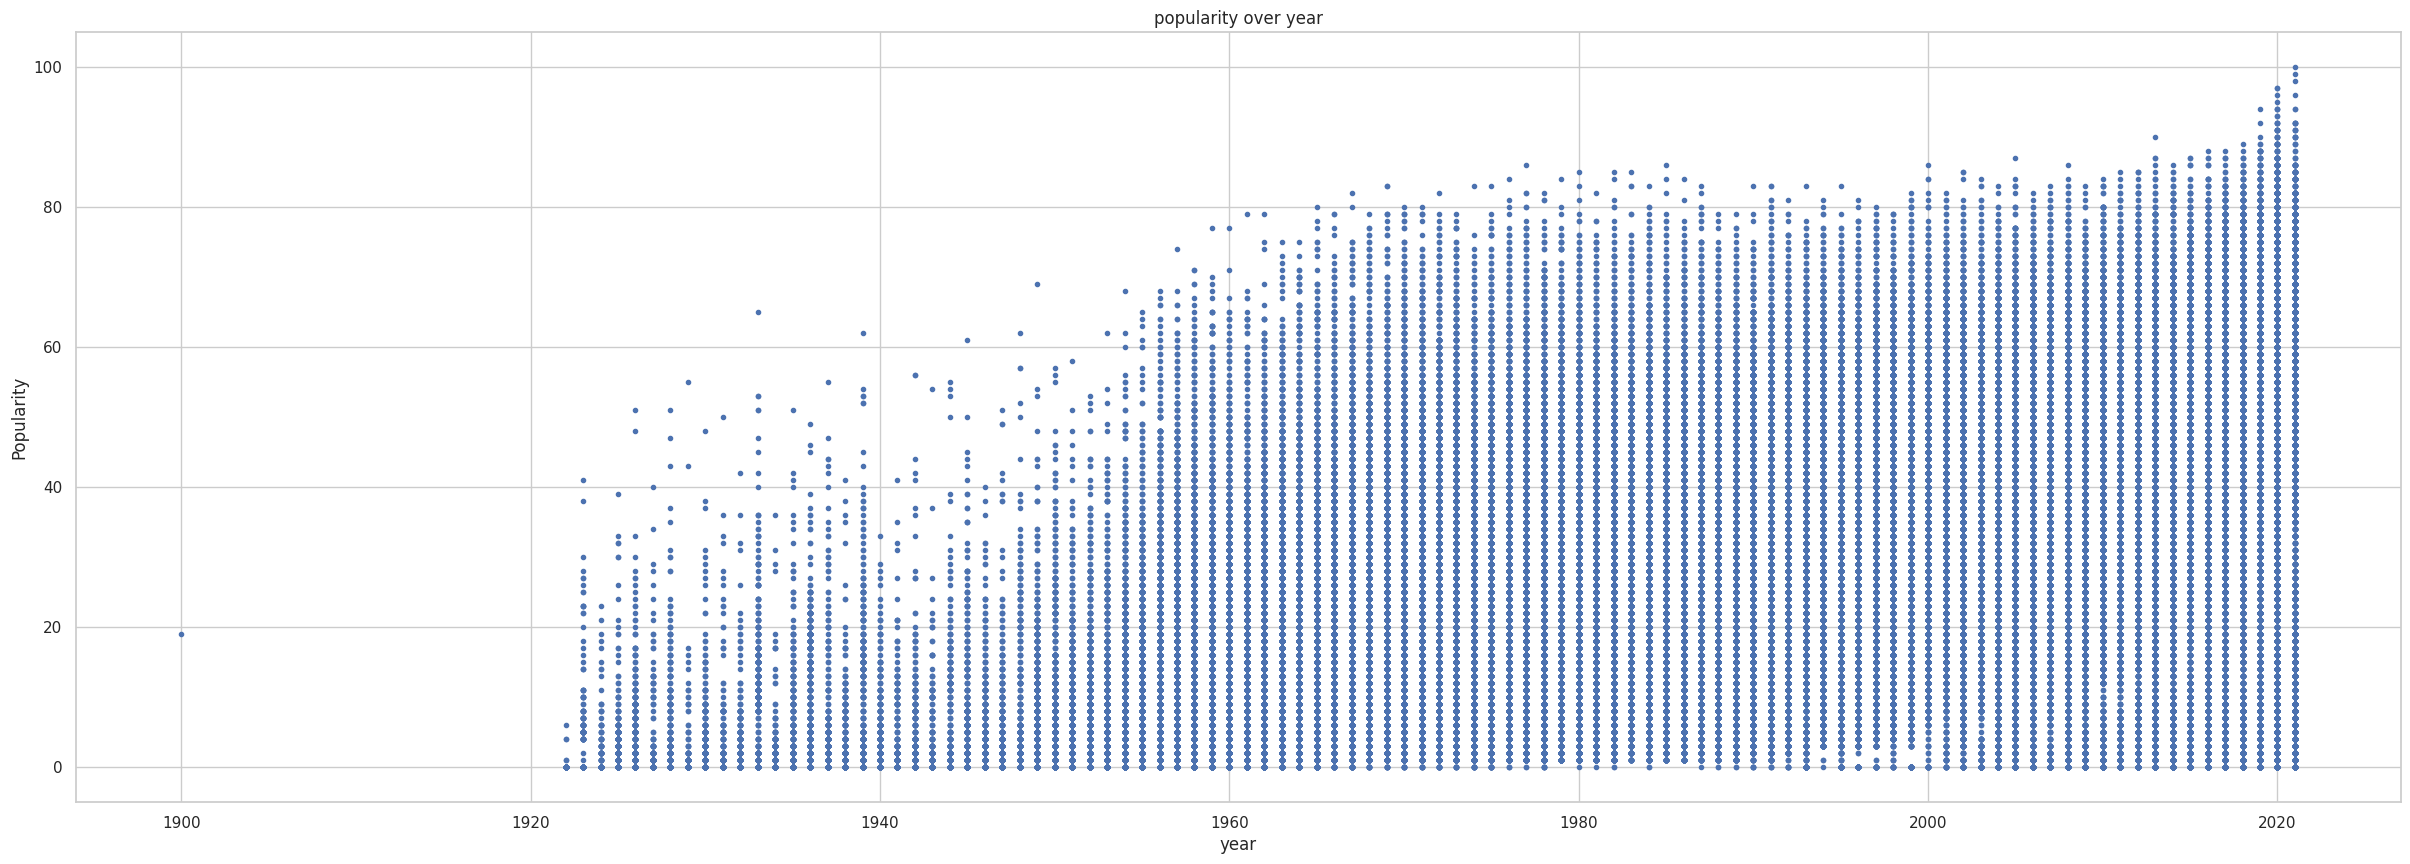

In [15]:
plt.figure(figsize=(30, 10))

xs = df["year"].to_numpy()
ys = df["popularity"].to_numpy()
plt.ylabel('Popularity')
plt.xlabel('year')
plt.title("popularity over year")
plt.plot(xs, ys, '.')
plt.show()

Text(0.5, 1.0, 'mean year for song popularity')

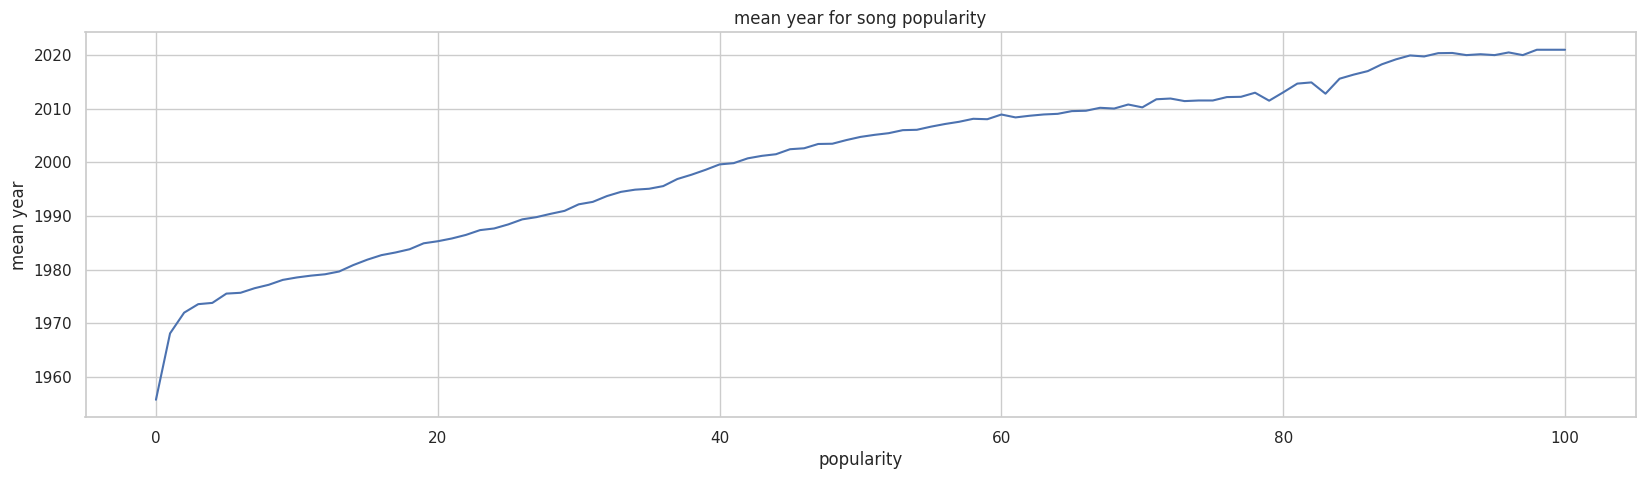

In [16]:
plt.figure(figsize=(20, 5))
sns.set(style="whitegrid")

# group by the song's popularity and then get the mean release year
x = df.groupby("popularity")["year"].mean()
axis = sns.lineplot(x=x.index, y=x)

axis.set_ylabel('mean year')
axis.set_xlabel('popularity')
axis.set_title("mean year for song popularity")

**Takeaway: newer tracks are more popular**

The more popular a track is, the newer it tends to be: mean release year climbs from roughly 1975 to 1980 for tracks with popularity between about 5 and 10, to about 2010 at popularity 60, to roughly 2020 for popularity of 90 or more. The popularity 0 group is a different mix, with a much older average release year (around 1956).

This fits how Spotify defines the score, which depends heavily on recent plays, so recent releases are favored by construction. That makes release year the main confounder for every audio feature comparison that follows.

### Relationship between energy and popularity

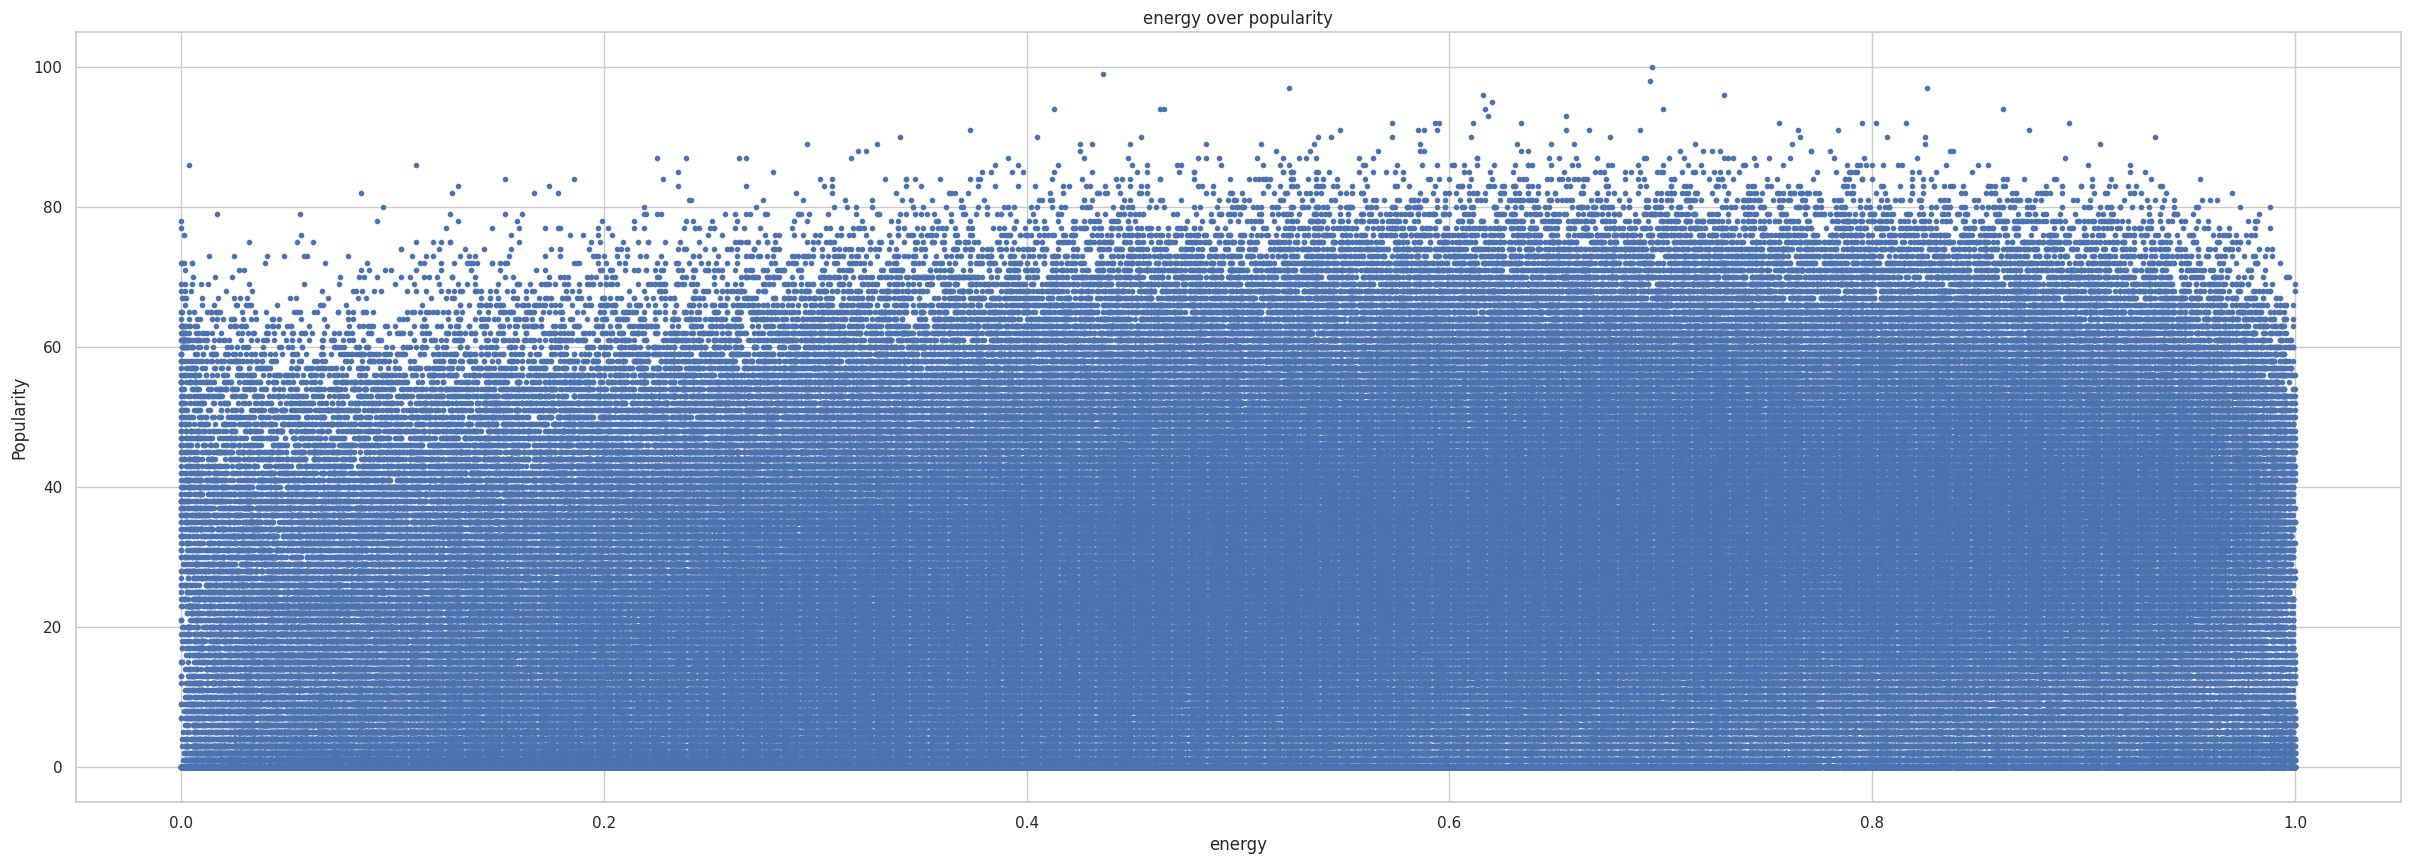

In [17]:
plt.figure(figsize=(30, 10))

xs = df["energy"].to_numpy()
ys = df["popularity"].to_numpy()
plt.ylabel('Popularity')
plt.xlabel('energy')
plt.title("energy over popularity")
plt.plot(xs, ys, '.')
plt.show()

Text(0.5, 1.0, 'mean energy for song popularity')

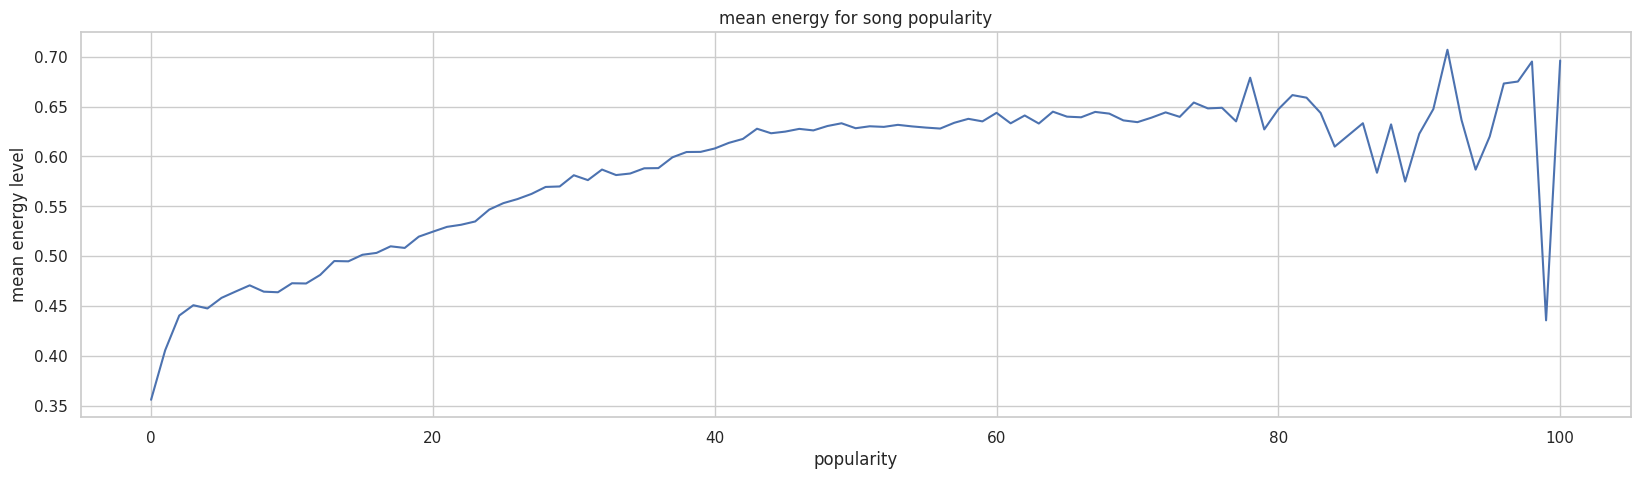

In [18]:
plt.figure(figsize=(20, 5))
sns.set(style="whitegrid")

# group by the song's popularity and then get the mean energy
x = df.groupby("popularity")["energy"].mean()
axis = sns.lineplot(x=x.index, y=x)

axis.set_ylabel('mean energy level')
axis.set_xlabel('popularity')
axis.set_title("mean energy for song popularity")

**Takeaway: energy and popularity (raw association)**

Mean energy rises with popularity, from about 0.4 to 0.45 for the least popular tracks to roughly 0.63 to 0.65 for popularity between 40 and 80. Above about 85 the line becomes erratic, most likely because those popularity scores contain few tracks.

This is a raw association. Energy has also risen over time and newer tracks are more popular, so part of this relationship is a release year effect. The regression section tests how much of it remains once release year is controlled for.

### Relationship between liveness and popularity

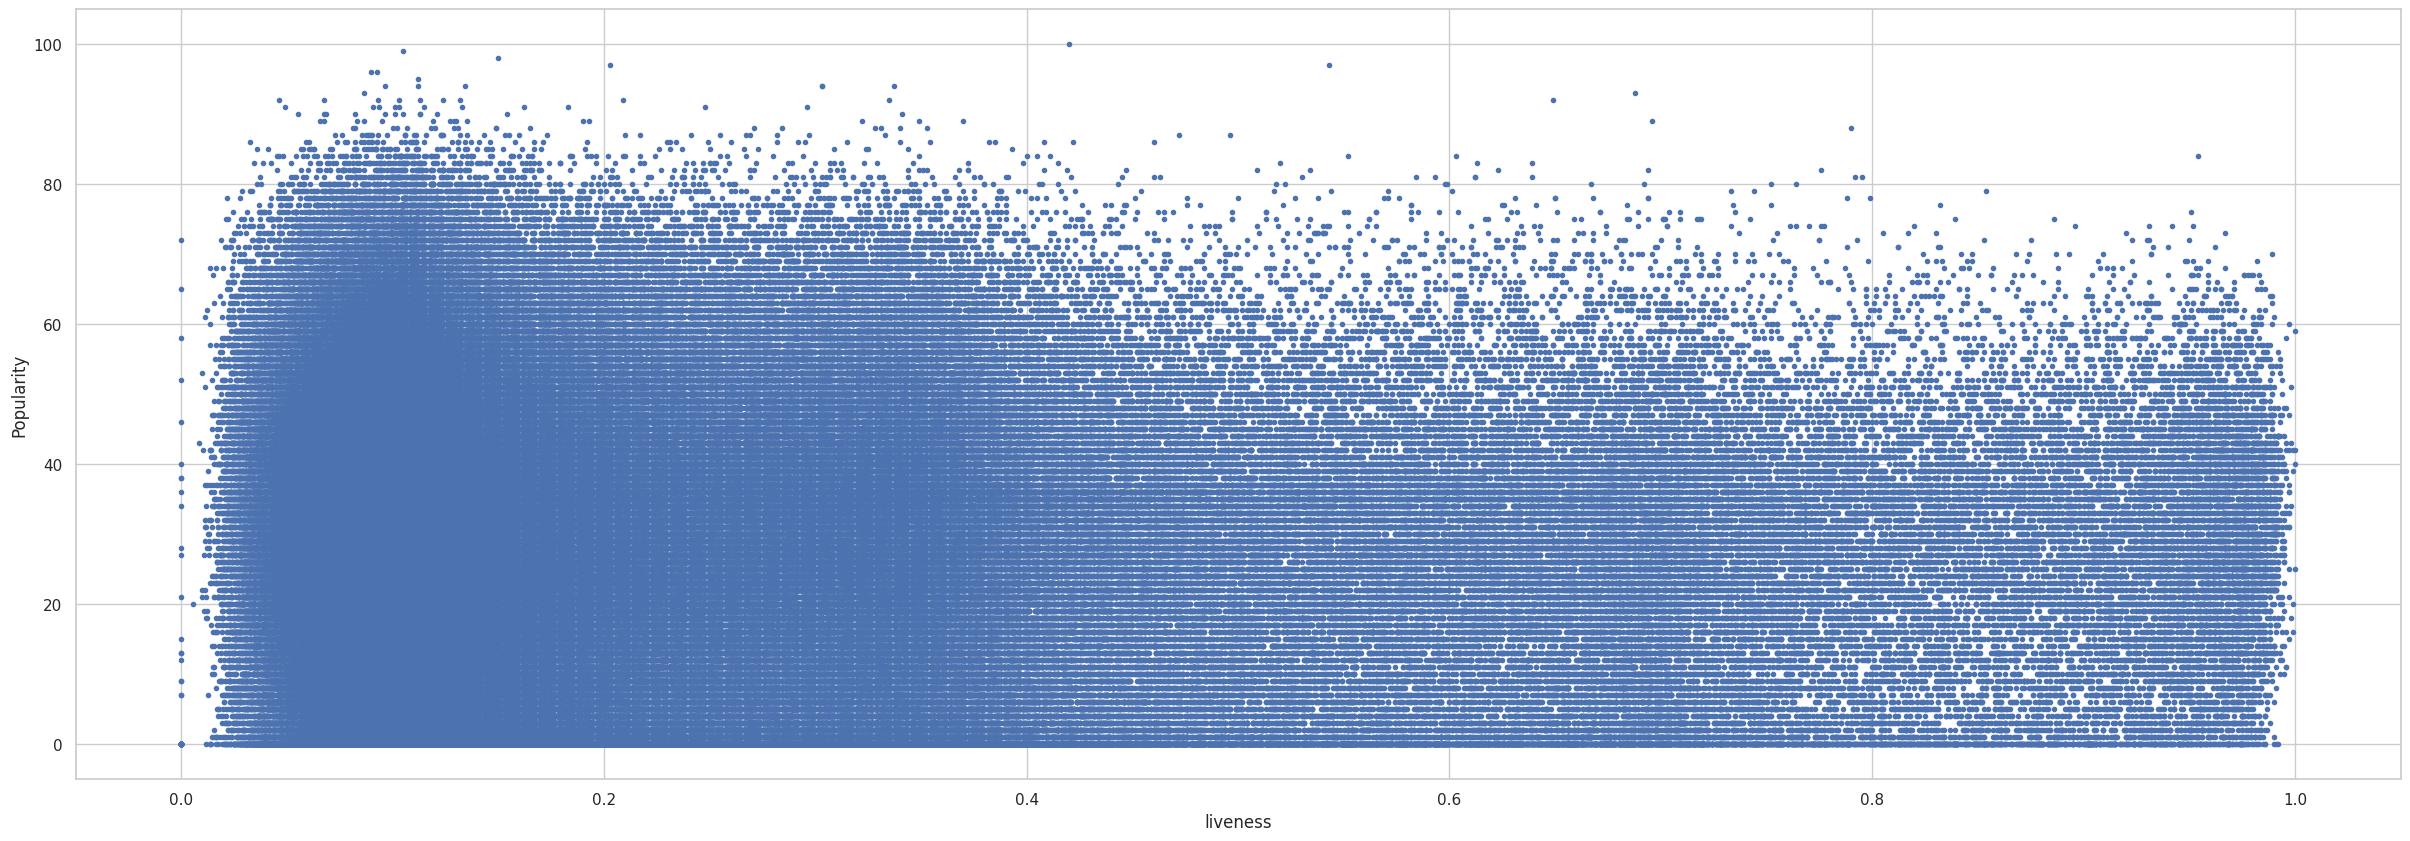

In [19]:
plt.figure(figsize=(30, 10))

xs = df["liveness"].to_numpy()
ys = df["popularity"].to_numpy()
plt.ylabel('Popularity')
plt.xlabel('liveness')

plt.plot(xs, ys, '.')
plt.show()

Text(0.5, 1.0, 'mean liveness for song popularity')

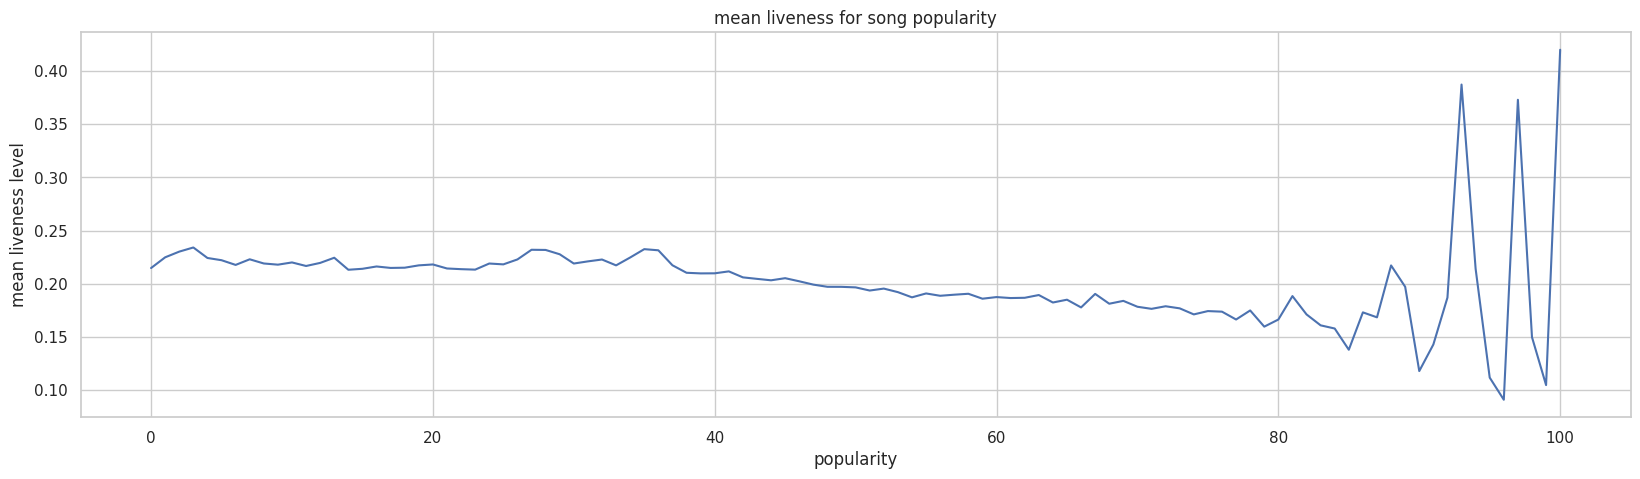

In [20]:
plt.figure(figsize=(20, 5))
sns.set(style="whitegrid")

# group by the song's popularity and then get the mean liveness
x = df.groupby("popularity")["liveness"].mean()
axis = sns.lineplot(x=x.index, y=x)

axis.set_ylabel('mean liveness level')
axis.set_xlabel('popularity')
axis.set_title("mean liveness for song popularity")


**Takeaway: liveness and popularity**

Mean liveness drifts down gently as popularity rises, from about 0.22 at low popularity to roughly 0.17 to 0.19 for popularity between 60 and 80. The large spikes above popularity 90 (swinging between roughly 0.1 and 0.4) most likely come from very few tracks in those bins and should not be read as a pattern.

Overall, liveness shows only a weak relationship with popularity.

### Relationship between acousticness and popularity

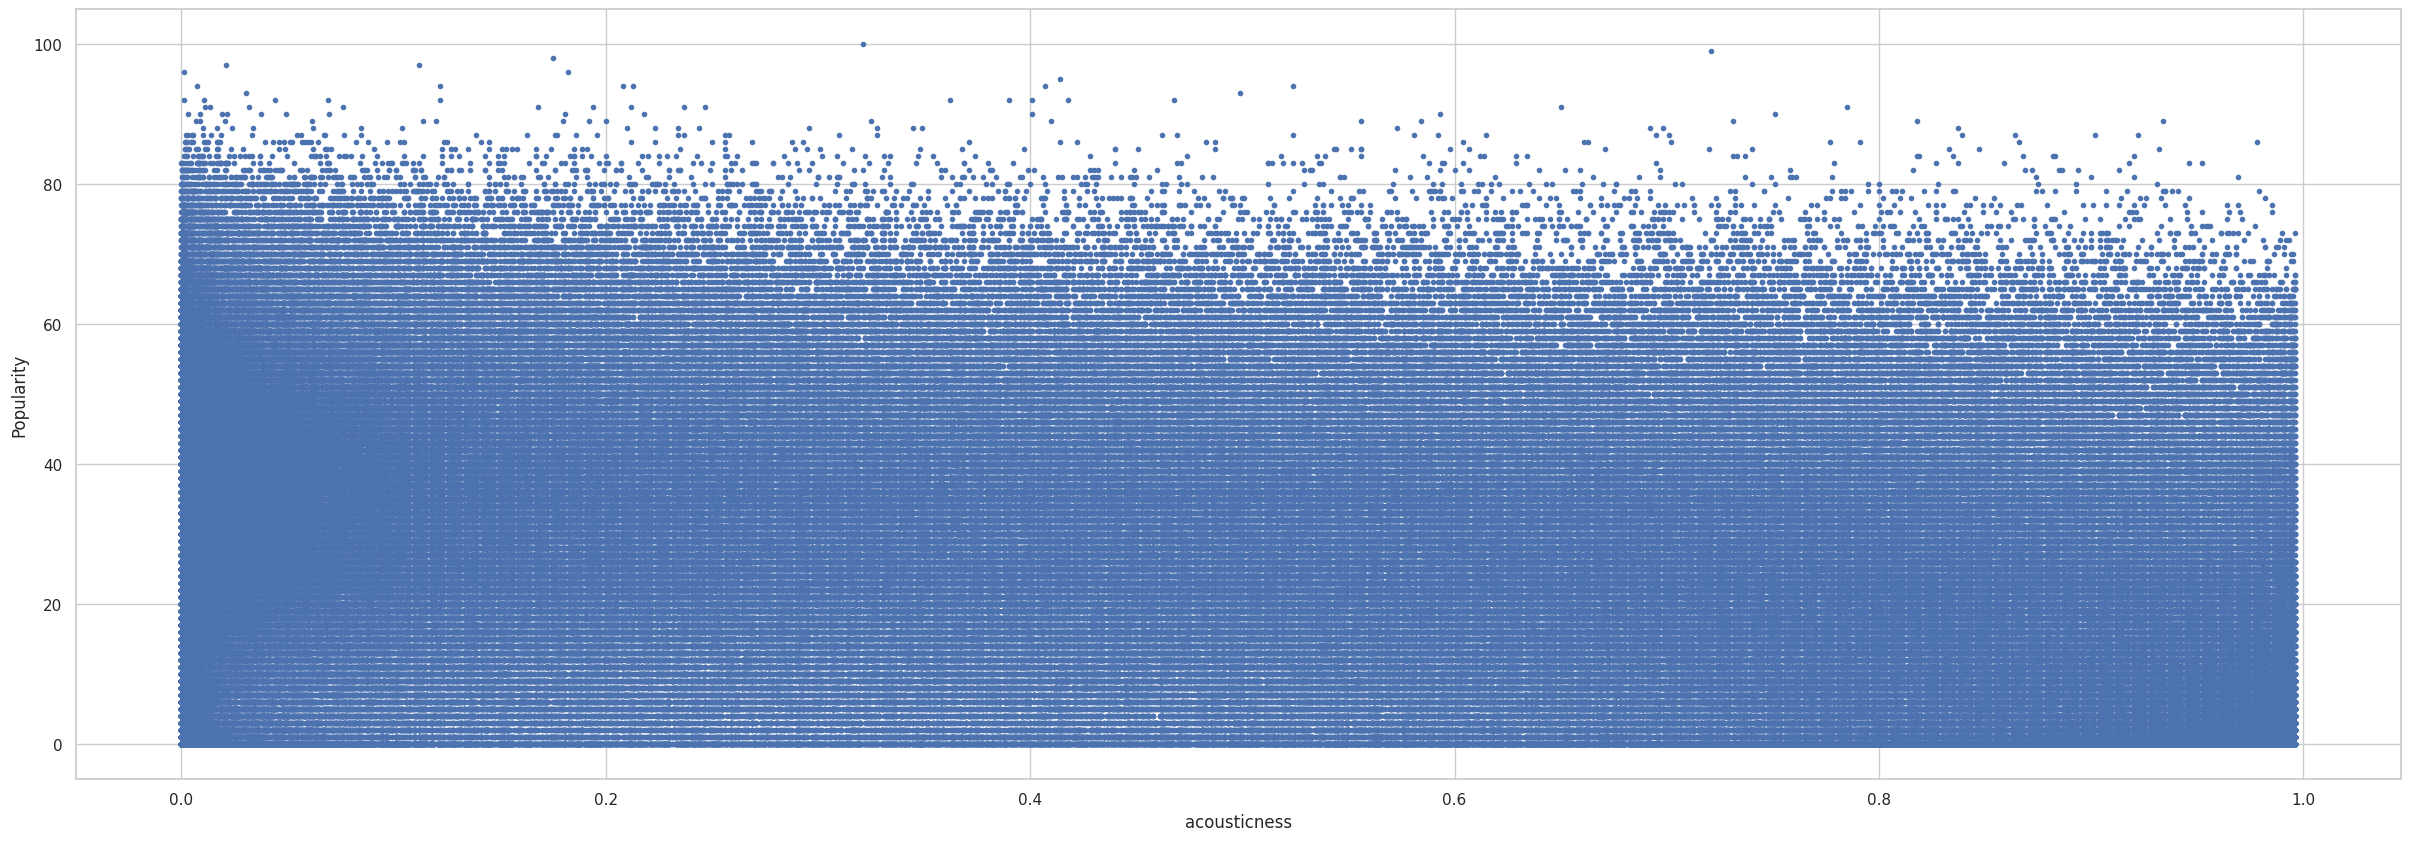

In [21]:
plt.figure(figsize=(30, 10))

xs = df["acousticness"].to_numpy()
ys = df["popularity"].to_numpy()
plt.ylabel('Popularity')
plt.xlabel('acousticness')

plt.plot(xs, ys, '.')
plt.show()

Text(0.5, 1.0, 'mean acousticness for song popularity')

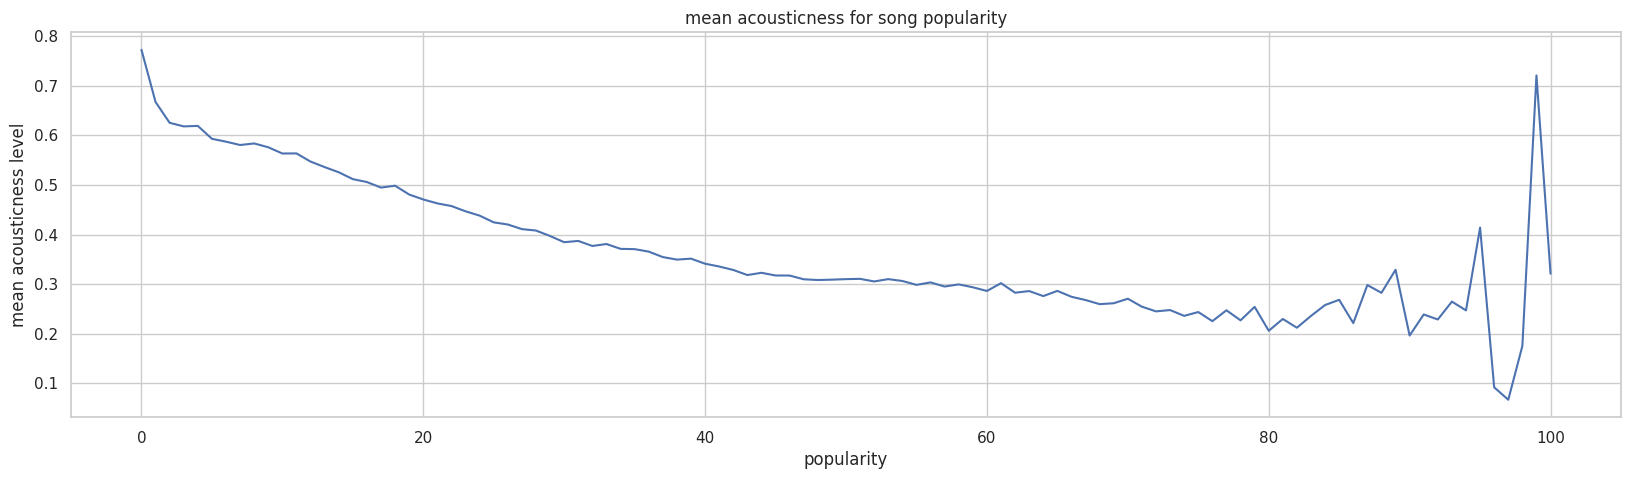

In [22]:
plt.figure(figsize=(20, 5))
sns.set(style="whitegrid")

# group by the song's popularity and then get the mean acousticness
x = df.groupby("popularity")["acousticness"].mean()
axis = sns.lineplot(x=x.index, y=x)

axis.set_ylabel('mean acousticness level')
axis.set_xlabel('popularity')
axis.set_title("mean acousticness for song popularity")

**Takeaway: acousticness and popularity (raw association)**

Mean acousticness falls as popularity rises, from about 0.6 to 0.75 for the least popular tracks to roughly 0.3 at popularity 50 and about 0.25 by popularity 80. Above about 90 the line becomes erratic, most likely because those scores contain few tracks.

More popular tracks are therefore less acoustic on average in this raw view. Acousticness has also fallen sharply over time and newer tracks are more popular, so this too is partly a release year effect.

# Regression Analysis

The exploratory plots above show associations, but they mix together several things that move at the same time (most importantly, release year). This section uses multiple linear regression (OLS) to separate them.

Everything below describes **associations in observational data**, not causal effects.

**Setup**
- Outcome: `popularity` (0 to 100)
- Audio features: `energy`, `danceability`, `acousticness`, `tempo`, `liveness`, each z-scored so a coefficient reads as "change in popularity points for a 1 standard deviation increase in that feature"
- Controls: release year (a separate fixed effect for every year, so the year pattern can take any shape) and explicit content
- Standard errors: heteroskedasticity robust (HC1)

Two models are fit so the effect of the controls is visible: **Model 1** uses audio features only, **Model 2** adds release year and explicit content.

In [23]:
audio_features = ['energy', 'danceability', 'acousticness', 'tempo', 'liveness']

reg_df = df[['popularity', 'year', 'explicit'] + audio_features].copy()
reg_df['explicit'] = reg_df['explicit'].astype(int)
reg_df['year'] = reg_df['year'].astype(int)

# z-score the audio features so coefficients are comparable across features
for col in audio_features:
    reg_df[col] = (reg_df[col] - reg_df[col].mean()) / reg_df[col].std()

rhs_audio = ' + '.join(audio_features)

# Model 1: audio features only
m1 = smf.ols(f'popularity ~ {rhs_audio}', data=reg_df).fit(cov_type='HC1')

# Model 2: audio features + explicit + a fixed effect for every release year
m2 = smf.ols(f'popularity ~ {rhs_audio} + explicit + C(year)', data=reg_df).fit(cov_type='HC1')

print(f'Observations: {int(m2.nobs):,}')
print(f'Model 1 (audio only)            R^2 = {m1.rsquared:.3f}')
print(f'Model 2 (+ explicit, year FE)   R^2 = {m2.rsquared:.3f}')

Observations: 586,601
Model 1 (audio only)            R^2 = 0.152
Model 2 (+ explicit, year FE)   R^2 = 0.384


In [24]:
def coef_table(model, terms):
    ci = model.conf_int().loc[terms]
    out = pd.DataFrame({
        'coef': model.params[terms],
        'ci_low': ci[0],
        'ci_high': ci[1],
        'p_value': model.pvalues[terms],
    })
    return out

terms = audio_features + ['explicit']
t1 = coef_table(m1, audio_features).add_suffix('_M1')
t2 = coef_table(m2, terms).add_suffix('_M2')
comparison = t1.join(t2, how='outer').loc[terms]
comparison.round(4)

,coef_M1,ci_low_M1,ci_high_M1,p_value_M1,coef_M2,ci_low_M2,ci_high_M2,p_value_M2
energy,1.3867,1.3230,1.4505,0.0000,-0.3311,-0.3863,-0.2759,0.0
danceability,1.6853,1.6390,1.7316,0.0000,0.6518,0.6112,0.6924,0.0
acousticness,-5.4154,-5.4781,-5.3527,0.0000,-1.2404,-1.2973,-1.1836,0.0
tempo,-0.0120,-0.0568,0.0328,0.6002,-0.1018,-0.1386,-0.0651,0.0
liveness,-0.9150,-0.9573,-0.8727,0.0000,-0.5813,-0.6193,-0.5434,0.0
explicit,NaN,NaN,NaN,NaN,8.2529,8.0230,8.4829,0.0


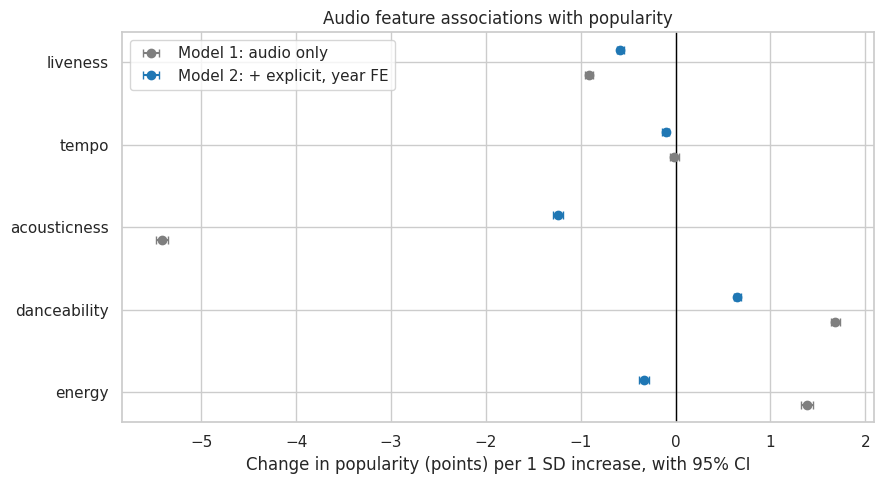

In [25]:
# Coefficient plot: how each audio feature's estimate changes once year and explicit content are controlled for
fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(audio_features))

for offset, model, label, color in [(-0.15, m1, 'Model 1: audio only', 'tab:gray'),
                                    (0.15, m2, 'Model 2: + explicit, year FE', 'tab:blue')]:
    ci = model.conf_int().loc[audio_features]
    coefs = model.params[audio_features]
    ax.errorbar(coefs, y_pos + offset,
                xerr=[coefs - ci[0], ci[1] - coefs],
                fmt='o', color=color, capsize=3, label=label)

ax.axvline(0, color='black', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(audio_features)
ax.set_xlabel('Change in popularity (points) per 1 SD increase, with 95% CI')
ax.set_title('Audio feature associations with popularity')
ax.legend()
plt.tight_layout()
plt.show()

**How to read this**

- Compare the gray and blue points for each feature. If an estimate shrinks, flips sign, or its interval crosses zero when moving from Model 1 to Model 2, the raw relationship was largely a release year effect.
- With this many rows almost every coefficient will be statistically significant, so focus on the size of each coefficient (popularity points per 1 SD) and its confidence interval rather than the p-value.
- Some audio features are related to each other (for example energy and acousticness, roughly -0.7 in the heatmap), so individual coefficients should be read together. The VIF check below tests whether this is severe enough to destabilize the estimates (values above about 5 would be a concern).

     feature  VIF
      energy 2.20
danceability 1.11
acousticness 2.10
       tempo 1.08
    liveness 1.05

Rule of thumb: VIF above about 5 suggests a feature is substantially explained by the others.


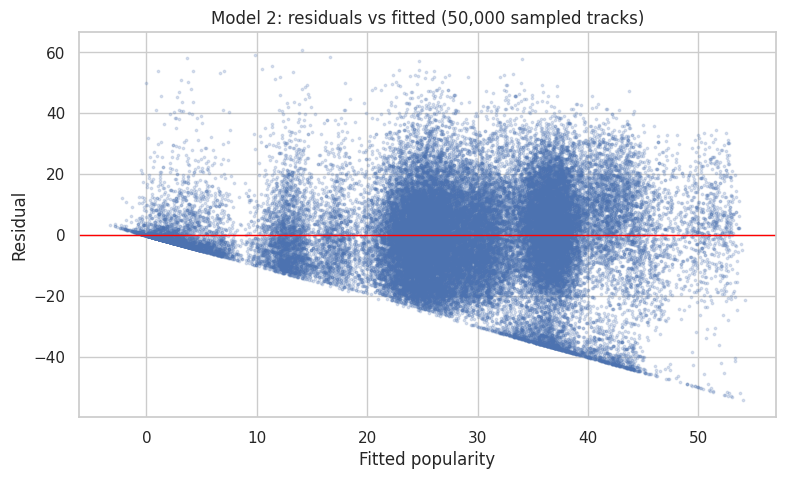

In [26]:
# Multicollinearity check (VIF) on a random sample of the audio features
sample = reg_df[audio_features].sample(100_000, random_state=42)
X = sample.assign(const=1.0)
vif = pd.DataFrame({
    'feature': audio_features,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(len(audio_features))],
})
print(vif.round(2).to_string(index=False))
print('\nRule of thumb: VIF above about 5 suggests a feature is substantially explained by the others.')

# Residuals vs fitted values for Model 2 (random sample for readability)
idx = reg_df.sample(50_000, random_state=42).index
fitted = m2.fittedvalues.loc[idx]
resid = m2.resid.loc[idx]

plt.figure(figsize=(9, 5))
plt.scatter(fitted, resid, s=3, alpha=0.2)
plt.axhline(0, color='red', linewidth=1)
plt.xlabel('Fitted popularity')
plt.ylabel('Residual')
plt.title('Model 2: residuals vs fitted (50,000 sampled tracks)')
plt.show()

**Model limitations.** `popularity` is bounded between 0 and 100 and is skewed, so OLS residuals will not be perfectly well behaved. The residual plot shows this directly: a hard diagonal lower edge, caused by popularity being floored at 0 (many tracks sit near 0), and distinct clusters of fitted values, most likely driven by the release year fixed effects. The estimates are best read as average linear associations, and robust standard errors are used so the confidence intervals do not depend on constant variance.

# Group Comparisons (A/B Style Hypothesis Tests)

This section asks the question the way an experiment would: do two groups of tracks differ in average popularity, and by how much?

Because these are observational data, the groups are not randomized, so a difference is an association and not the effect of changing a feature. To limit the biggest confounder, both comparisons are restricted to tracks released in 2010 or later, so old and new tracks are not being compared against each other.

**Method for each comparison**
- Welch's two sample t-test (does not assume equal variances)
- 95% confidence interval for the difference in mean popularity
- Cohen's d as the effect size (about 0.2 is small, 0.5 medium, 0.8 large)
- Mann-Whitney U test as a robustness check, since popularity is not normally distributed

**Multiple comparisons.** Two tests are run, so a Bonferroni adjusted significance level of 0.05 / 2 = 0.025 is used.

In [27]:
def compare_groups(a, b, name):
    """Welch t-test, CI for the mean difference, Cohen's d, and a Mann-Whitney check for group a vs group b."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    na, nb = len(a), len(b)
    diff = a.mean() - b.mean()

    t_stat, p_welch = stats.ttest_ind(a, b, equal_var=False)
    se = np.sqrt(a.var(ddof=1) / na + b.var(ddof=1) / nb)
    ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se

    pooled_sd = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    cohens_d = diff / pooled_sd

    _, p_mw = stats.mannwhitneyu(a, b, alternative='two-sided')

    return pd.Series({
        'n_A': na,
        'n_B': nb,
        'mean_A': a.mean(),
        'mean_B': b.mean(),
        'diff (A - B)': diff,
        '95% CI low': ci_low,
        '95% CI high': ci_high,
        'Cohen d': cohens_d,
        'Welch p': p_welch,
        'Mann-Whitney p': p_mw,
    }, name=name)

In [28]:
recent = df[df['year'] >= 2010].copy()
alpha = 0.05 / 2  # Bonferroni adjustment for 2 tests

# Test 1: high energy vs low energy (median split within the 2010+ tracks)
median_energy = recent['energy'].median()
high_energy = recent.loc[recent['energy'] > median_energy, 'popularity']
low_energy = recent.loc[recent['energy'] <= median_energy, 'popularity']

# Test 2: explicit vs not explicit tracks (2010+)
explicit_pop = recent.loc[recent['explicit'] == 1, 'popularity']
clean_pop = recent.loc[recent['explicit'] == 0, 'popularity']

results = pd.DataFrame([
    compare_groups(high_energy, low_energy, 'High vs low energy (A = high)'),
    compare_groups(explicit_pop, clean_pop, 'Explicit vs not explicit (A = explicit)'),
]).T

print(results.round(4).to_string())
print()
for name in results.columns:
    p = results.loc['Welch p', name]
    verdict = 'significant' if p < alpha else 'not significant'
    print(f'{name}: Welch p = {p:.2e} -> {verdict} at the Bonferroni adjusted level of {alpha}')

                High vs low energy (A = high)  Explicit vs not explicit (A = explicit)
n_A                                62620.0000                               17090.0000
n_B                                62843.0000                              108373.0000
mean_A                                37.5004                                  49.0951
mean_B                                41.6651                                  38.0870
diff (A - B)                          -4.1647                                  11.0081
95% CI low                            -4.3919                                  10.7073
95% CI high                           -3.9374                                  11.3090
Cohen d                               -0.2029                                   0.5426
Welch p                                0.0000                                   0.0000
Mann-Whitney p                         0.0000                                   0.0000

High vs low energy (A = high): Welch p = 3

**How to read this**

- The mean difference and its confidence interval say how many popularity points apart the groups are. Cohen's d says whether that gap is large relative to how much popularity varies across tracks.
- A tiny p-value with a small Cohen's d means the difference is real in this dataset but not practically large. With this much data, that combination is expected.
- If the Mann-Whitney result agrees with the Welch result, the conclusion does not depend on the normality assumption.
- These are not randomized groups, so none of this shows that making a track more energetic or explicit would change its popularity.

# Summary of Results

The cell below prints the key numbers directly from the fitted models and tests, so they always match the current run of the notebook.

In [29]:
# Summary of key results, computed from the fitted models and tests above so the numbers always match the current data
print(f"Tracks used in the regression: {int(m2.nobs):,}")
print(f"R^2, audio features only (Model 1):                 {m1.rsquared:.3f}")
print(f"R^2, adding explicit content and release year (Model 2): {m2.rsquared:.3f}")

print("\nAudio feature coefficients in popularity points per 1 SD, Model 1 -> Model 2:")
ci1 = m1.conf_int()
ci2 = m2.conf_int()
for f in audio_features:
    raw, ctl = m1.params[f], m2.params[f]
    lo, hi = ci2.loc[f]
    raw_lo, raw_hi = ci1.loc[f]
    if lo <= 0 <= hi:
        note = 'not distinguishable from zero once release year is controlled'
    elif raw_lo <= 0 <= raw_hi:
        note = 'no detectable raw association; a small one appears once release year is controlled'
    elif np.sign(raw) != np.sign(ctl):
        note = 'sign reverses once release year is controlled'
    elif abs(ctl) < abs(raw):
        note = f'shrinks by {100 * (1 - abs(ctl) / abs(raw)):.0f}% once release year is controlled'
    else:
        note = f'grows by {100 * (abs(ctl) / abs(raw) - 1):.0f}% once release year is controlled'
    print(f"  {f:<13} {raw:+.2f} -> {ctl:+.2f}   95% CI (Model 2): {lo:+.2f} to {hi:+.2f}   [{note}]")

lo, hi = ci2.loc['explicit']
print(f"\nExplicit content (Model 2, holding audio features and release year fixed): "
      f"{m2.params['explicit']:+.2f} points, 95% CI {lo:+.2f} to {hi:+.2f}")

print("\nGroup comparisons, tracks released 2010 or later (A minus B):")
for name in results.columns:
    r = results[name]
    print(f"  {name}: {r['diff (A - B)']:+.2f} points, 95% CI {r['95% CI low']:+.2f} to {r['95% CI high']:+.2f}, "
          f"Cohen's d = {r['Cohen d']:+.2f}")

Tracks used in the regression: 586,601
R^2, audio features only (Model 1):                 0.152
R^2, adding explicit content and release year (Model 2): 0.384

Audio feature coefficients in popularity points per 1 SD, Model 1 -> Model 2:
  energy        +1.39 -> -0.33   95% CI (Model 2): -0.39 to -0.28   [sign reverses once release year is controlled]
  danceability  +1.69 -> +0.65   95% CI (Model 2): +0.61 to +0.69   [shrinks by 61% once release year is controlled]
  acousticness  -5.42 -> -1.24   95% CI (Model 2): -1.30 to -1.18   [shrinks by 77% once release year is controlled]
  tempo         -0.01 -> -0.10   95% CI (Model 2): -0.14 to -0.07   [no detectable raw association; a small one appears once release year is controlled]
  liveness      -0.92 -> -0.58   95% CI (Model 2): -0.62 to -0.54   [shrinks by 36% once release year is controlled]

Explicit content (Model 2, holding audio features and release year fixed): +8.25 points, 95% CI +8.02 to +8.48

Group comparisons, tracks re

# Conclusion

**Scope.** This project examines how audio features, explicit content, and release year relate to track popularity in the Spotify 1921 to 2020 dataset (586,672 tracks). Every finding is an association in observational data. Nothing here shows that changing a feature would change a track's popularity.

**1. Release year is the dominant pattern.** It has the strongest correlation with popularity of any variable in the correlation matrix, and mean release year climbs steadily with popularity. Spotify's popularity score depends heavily on recent plays, so newer tracks are favored by construction and older tracks are disadvantaged regardless of quality.

**2. Release year also confounds the audio features.** Across the century acousticness fell, while energy, loudness, and more recently danceability rose. Because newer tracks are both more popular and sound different, a raw feature versus popularity relationship mixes a real association with a time effect. That is why the regression compares a model without year (Model 1) against a model with a fixed effect for every release year plus explicit content (Model 2). Where the two disagree, Model 2 is the better estimate of a feature's association with popularity, and the summary of results above gives the exact figures for this run.

**Key findings (586,601 tracks)**
- **Energy shows the clearest confounding.** Its association with popularity is +1.39 points per 1 SD on its own, but reverses to -0.33 (95% CI -0.39 to -0.28) once release year and explicit content are controlled.
- **Other raw associations shrink a lot.** Acousticness goes from -5.42 to -1.24 (about 77% smaller), danceability from +1.69 to +0.65 (about 61% smaller), and liveness from -0.92 to -0.58. Tempo has no detectable raw association (p = 0.60) and a very small negative one with controls (-0.10).
- **Every audio feature is small once year is controlled.** All associations are within about 1.3 popularity points per 1 SD on a 0 to 100 scale. The largest VIF is about 2.2, well under the usual concern level of 5, so overlap between features is not distorting these estimates.
- **Explicit content is the largest association in the model.** Explicit tracks score about 8.3 points higher (95% CI 8.0 to 8.5), holding audio features and release year fixed. This may partly reflect genre and listening patterns that are not in the data.
- **Group comparisons, tracks released 2010 or later.** Explicit tracks average 11.0 points higher in popularity than non explicit tracks (95% CI 10.7 to 11.3, Cohen's d = 0.54, a medium effect). Tracks in the high energy half average 4.2 points lower than the low energy half (95% CI 3.9 to 4.4 points lower, Cohen's d = -0.20, a small effect).
- **The group comparisons and the regression answer different questions.** Both agree in direction (explicit higher, energy lower), but the group comparisons do not hold other audio features, explicit content, or exact release year fixed. That is why the raw explicit gap (11.0) is larger than the regression estimate (8.3), and why the energy gap between halves (4.2 points) is much larger than the regression's per 1 SD estimate (0.33 points). The regression numbers are the better estimates of each variable's own association.

**3. Effect sizes matter more than p-values.** With hundreds of thousands of tracks, almost any difference is statistically significant. The coefficients, confidence intervals, and Cohen's d values in the summary show whether a difference is large enough to matter (a Cohen's d near 0.2 is small, near 0.5 is medium).

**4. Much of popularity is left unexplained.** Adding release year and explicit content raises R-squared from 0.15 to 0.38, which still leaves roughly 60% of the variation in popularity unexplained.

**Limitations**
- The data are observational. The group comparisons are restricted to tracks from 2010 onward, which reduces but does not remove confounding by release year.
- Popularity is bounded between 0 and 100 and is skewed, so OLS is an approximation. Robust standard errors and a rank based Mann-Whitney check limit how much the conclusions depend on its assumptions.
- The audio features are Spotify's own model outputs, not direct measurements.
- Artist, marketing, playlist placement, lyrics, and cultural context are not in the data and almost certainly matter a great deal.
- Years before about 1940 contain few tracks and very noisy averages, and the highest popularity scores contain few tracks, so patterns at those extremes are unreliable.